# Does It Survive a Shift? Solution

A solution of the practice task *Does it survive a shift?*, in this folder's [README](../README.md#practice): try the task before reading it. The classifier is [k-nearest neighbours](../algorithms/neighbours/knn.ipynb), and `shift_image` is the one in the solution of [numpy-mnist](https://github.com/avidaldo/numpy-mnist).

## The Data

MNIST from OpenML, as in [A classifier in depth](../evaluation/deep-dives/mnist_classifier_in_depth.ipynb): 70,000 handwritten digits of 28×28 pixels, each flattened into a row of 784 numbers. The first 60,000 are the usual training set and the last 10,000 the test set. The task trains on the first 10,000 only, so that each fit takes seconds.

In [1]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", as_frame=False)
X, y = mnist.data, mnist.target
X.shape

(70000, 784)

In [2]:
X_train, y_train = X[:10_000], y[:10_000]
X_test, y_test = X[60_000:], y[60_000:]
X_train.shape, X_test.shape

((10000, 784), (10000, 784))

## A Baseline on the Test Set

In [3]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
knn.score(X_test, y_test)

0.9442

About 94% of the test digits are classified correctly. The test set was prepared like the training set: every digit centred in its frame by the same process.

## The Same Test Images, Shifted

In [4]:
import numpy as np


def shift_image(image: np.ndarray, dx: int, dy: int) -> np.ndarray:
    height, width = image.shape
    shifted = np.zeros_like(image)
    # the rows and columns that stay inside the frame, where they land and where they come from
    destination_rows = slice(max(dy, 0), height + min(dy, 0))
    destination_cols = slice(max(dx, 0), width + min(dx, 0))
    source_rows = slice(max(-dy, 0), height + min(-dy, 0))
    source_cols = slice(max(-dx, 0), width + min(-dx, 0))
    shifted[destination_rows, destination_cols] = image[source_rows, source_cols]
    return shifted

The rows of `X` are flat, so each one is reshaped to its 28×28 image, shifted, and flattened back:

In [5]:
def shift_rows(rows: np.ndarray, dx: int, dy: int) -> np.ndarray:
    return np.array([shift_image(row.reshape(28, 28), dx, dy).ravel() for row in rows])


X_test_right = shift_rows(X_test, dx=3, dy=0)

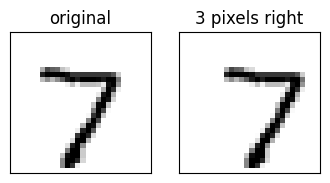

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(4, 2))
for ax, image, title in zip(axes, [X_test[0], X_test_right[0]], ["original", "3 pixels right"]):
    ax.imshow(image.reshape(28, 28), cmap="binary")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

In [7]:
knn.score(X_test_right, y_test)

0.4312

Accuracy falls from 94% to 43%, on digits that any person still reads at once. k-nearest neighbours compares pixels in the same positions: shifted 3 pixels, a digit's strokes fall where the training images of its class are blank, and its nearest neighbours belong to other classes.

## Training on Shifted Copies

Four copies of each training image, shifted 3 pixels right, left, down and up, join the originals: 50,000 rows.

In [8]:
shifts = [(3, 0), (-3, 0), (0, 3), (0, -3)]
X_augmented = np.concatenate([X_train] + [shift_rows(X_train, dx, dy) for dx, dy in shifts])
y_augmented = np.concatenate([y_train] * (len(shifts) + 1))
X_augmented.shape

(50000, 784)

In [9]:
knn_augmented = KNeighborsClassifier()
knn_augmented.fit(X_augmented, y_augmented)
knn_augmented.score(X_test, y_test), knn_augmented.score(X_test_right, y_test)

(0.939, 0.9425)

The shifted test images are now as easy as the original ones, about 94%, and the original test set loses almost nothing (93.9% against 94.4%).

## A Shift It Hasn't Seen

The copies cover four shifts. A diagonal one, 2 pixels right and 2 down, is none of them:

In [10]:
X_test_diagonal = shift_rows(X_test, dx=2, dy=2)
knn.score(X_test_diagonal, y_test), knn_augmented.score(X_test_diagonal, y_test)

(0.3934, 0.803)

From 39% to 80%: better, because the shifted copies come closer to these images than the originals do, but far from 94%. The augmented model handles the shifts it was shown, not shifting in general. Convolutional networks, in Neural networks *(coming)*, build part of that tolerance into the model itself, and are trained on augmented data too.

## How Far Can That 94% Be Trusted?

The shifted test set has done two jobs: it showed the problem, and it judged the fix. Two things make the fix's 94% optimistic:

- **The fix was chosen after looking at the test set.** Once a test score has led to a change in the model, the next test score is no longer an honest estimate ([Validation and model selection](../ml-fundamentals/validation_and_model_selection.ipynb)). Here only one fix was tried, so the effect is small; trying copies shifted 2, 3 and 4 pixels and keeping the best would make it larger.
- **The fix contains the test condition.** The test digits were shifted 3 pixels right, and 3 pixels right is one of the four copies. The 94% says that the model handles the shift it was trained on, not that it handles digits that aren't centred.

A real application rarely brings one exact shift. A closer description of the condition: digits off centre by up to 3 pixels horizontally and up to 3 vertically, each by its own random amount:

In [11]:
rng = np.random.default_rng(0)


def random_shift_rows(rows: np.ndarray, max_shift: int) -> np.ndarray:
    # one (dx, dy) pair per row, each from -max_shift to max_shift: the upper bound of integers() is excluded
    offsets = rng.integers(-max_shift, max_shift + 1, size=(len(rows), 2))
    return np.array([shift_image(row.reshape(28, 28), dx, dy).ravel() for row, (dx, dy) in zip(rows, offsets)])

Choices need data of their own, a **validation set**, and it must contain the condition too: a validation set of centred digits would choose a model for centred digits. The models were trained on only the first 10,000 of the 60,000 training images, so the next 10,000 can be the validation set without touching the test set. Two shifted versions of it: one like the shifted test set above, every digit 3 pixels right, and one with random shifts:

In [12]:
X_valid, y_valid = X[10_000:20_000], y[10_000:20_000]
X_valid_right = shift_rows(X_valid, dx=3, dy=0)
X_valid_random = random_shift_rows(X_valid, max_shift=3)

A second candidate: four copies of each training image, as before, but each shifted at random within the same range instead of by the four fixed shifts. The labels are `y_augmented` again, since the copies come in the same order:

In [13]:
X_random_copies = np.concatenate([X_train] + [random_shift_rows(X_train, max_shift=3) for _ in range(4)])
knn_random_copies = KNeighborsClassifier()
knn_random_copies.fit(X_random_copies, y_augmented)
knn_augmented.score(X_valid_right, y_valid), knn_random_copies.score(X_valid_right, y_valid)

(0.9442, 0.8962)

Judged on digits all shifted 3 pixels right, the fixed copies win, 94% against 90%: they contain that exact shift. Judged on random shifts:

In [14]:
knn_augmented.score(X_valid_random, y_valid), knn_random_copies.score(X_valid_random, y_valid)

(0.8115, 0.8978)

The order flips: 81% against 90%. On digits off centre in any direction, the fixed copies' 94% becomes 81%. **A set built from one exact change rewards the fix built for that change**, so a validation set has to describe the condition, not one instance of it. The copies shifted at random are chosen.

Only now is the test set used, once, with random shifts of its own. [Validation and model selection](../ml-fundamentals/validation_and_model_selection.ipynb#testing-once) trains the chosen model again on the training and validation images together; here it keeps the same 10,000 training images, so that its score compares with the others in this notebook:

In [15]:
X_test_random = random_shift_rows(X_test, max_shift=3)
knn_random_copies.score(X_test, y_test), knn_random_copies.score(X_test_random, y_test)

(0.9429, 0.9022)

94.3% on the original test digits and 90.2% on shifted ones, close to the 89.8% the validation set predicted. That is the estimate to report for digits off centre by up to 3 pixels, and nothing is changed after seeing it.

## What the Gap Says

- **A test set measures the conditions it contains.** 94% on the test set is a promise about digits prepared like the training digits. It says nothing about digits written, scanned or cropped differently: shifted 3 pixels, the same model gets 43%.
- **Real conditions have to be in the test set, and in the validation set.** The test set stands for the data the model will meet in production ([Overfitting and the train/test split](../ml-fundamentals/overfitting_and_the_split.ipynb)) only as far as it resembles that data. If the application will see shifted digits, the test set needs them too, and so does the validation set, which chooses the model.
- **Augmentation covers what you anticipate.** Shifted copies make the model handle the shifts they contain (94% on the 3-pixel shift), but a shift they don't contain stays hard (80% on the diagonal one). A good answer measures both: the change the training data covers, and one it doesn't.
- **A set built from the fix's own change flatters the fix.** On validation digits shifted 3 pixels right, the four fixed copies scored 94% and beat copies shifted at random (90%); on random shifts they scored 81% against 90%. Describe the condition as a range, choose on a validation set that contains it, and test the chosen model once.

## Every Model That Reads Pixels Falls *(deep dive)*

k-nearest neighbours is not unusually fragile. Logistic regression and a random forest, trained on the same 10,000 images, fall in the same way. Every model in these last sections is measured on the validation set, centred and shifted at random; first, k-nearest neighbours again, for reference:

In [16]:
knn.score(X_valid, y_valid), knn.score(X_valid_random, y_valid)

(0.9452, 0.5049)

Logistic regression's solver needs the pixels on a small scale: dividing them by 255 puts every pixel between 0 and 1, the same way for all of them:

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

logistic = make_pipeline(FunctionTransformer(lambda pixels: pixels / 255), LogisticRegression(max_iter=1000))
logistic.fit(X_train, y_train)
logistic.score(X_valid, y_valid), logistic.score(X_valid_random, y_valid)

(0.8984, 0.4362)

In [18]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(random_state=0)
forest.fit(X_train, y_train)
forest.score(X_valid, y_valid), forest.score(X_valid_random, y_valid)

(0.9484, 0.5109)

All three lose around 40 points, and each fails in its own way:

- k-nearest neighbours compares whole images pixel by pixel: a stroke moved 3 pixels counts as ink missing where the stroke was and extra ink where it is now.
- Logistic regression has one weight per pixel and class, like a stencil of each digit, and the shifted digit slides off its stencil.
- Each question in a tree is about a single pixel, such as whether pixel 350 is darker than some value; after the shift, the ink that answered it is somewhere else.

Behind the three lies one reason: each reads the 784 pixels as 784 separate columns, with no idea which pixels are neighbours.

An experiment shows how little these models know about images: shuffle the 784 columns, the same way in every image, training and validation alike.

In [19]:
permutation = rng.permutation(784)
X_train_shuffled, X_valid_shuffled = X_train[:, permutation], X_valid[:, permutation]

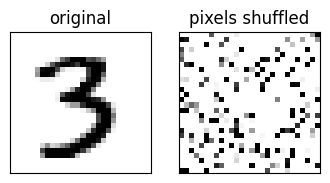

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(4, 2))
for ax, image, title in zip(axes, [X_valid[0], X_valid_shuffled[0]], ["original", "pixels shuffled"]):
    ax.imshow(image.reshape(28, 28), cmap="binary")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

Nobody can read the shuffled digit. k-nearest neighbours doesn't notice:

In [21]:
knn_shuffled = KNeighborsClassifier()
knn_shuffled.fit(X_train_shuffled, y_train)
knn_shuffled.score(X_valid_shuffled, y_valid)

0.9452

94.5%, exactly the score it had on the real images: the distance between two images adds up the differences pixel by pixel, and the order of the terms doesn't change a sum. The model never knew that pixel 350 sits next to pixel 351, so to it a shifted digit is just a different set of columns; logistic regression and the forest don't know it either. Convolutional networks, in Neural networks *(coming)*, slide the same small filter over every position of the image, so a stroke is recognised wherever it is: that is where part of their tolerance to shifts comes from.

## Re-centring Instead of Augmenting *(deep dive)*

MNIST's digits are centred because its authors centred them: each digit was moved so that its centre of mass, the average position of its ink weighted by how dark it is, sits at the centre of the 28×28 frame. Shifting a digit undoes that step. Applying the same step to every image, before training and before predicting, undoes the shift without a single copy:

In [22]:
# row_positions[i, j] is i and col_positions[i, j] is j
row_positions, col_positions = np.indices((28, 28))


def recentre(image: np.ndarray) -> np.ndarray:
    mass = image.sum()
    centre_row = (row_positions * image).sum() / mass
    centre_col = (col_positions * image).sum() / mass
    # every image goes to the same target pixel, so its exact choice doesn't matter
    return shift_image(image, dx=round(14 - centre_col), dy=round(14 - centre_row))


def recentre_rows(rows: np.ndarray) -> np.ndarray:
    return np.array([recentre(row.reshape(28, 28)).ravel() for row in rows])

In [23]:
knn_recentred = KNeighborsClassifier()
knn_recentred.fit(recentre_rows(X_train), y_train)
knn_recentred.score(recentre_rows(X_valid), y_valid), knn_recentred.score(recentre_rows(X_valid_random), y_valid)

(0.9452, 0.9445)

94.5% on centred digits and 94.4% on shifted ones, with 10,000 training images instead of 50,000. A shift by whole pixels moves the centre of mass by exactly as much, so a shifted digit and its original become the same image once re-centred; the only ones that don't are those whose ink the shift pushed partly out of the frame. It is the rule of [the test set stands for production](../ml-fundamentals/overfitting_and_the_split.ipynb#the-test-set-stands-for-production), applied to a preparation step: new images go through the same preparation as the training images, unchanged. MNIST's centring was such a step, and the shifted digits had skipped it.

The comparison flatters re-centring: it undoes exactly the change that was made, on a clean black background. A stray mark, noise or a second digit in the frame moves the centre of mass, and no centre of mass undoes a rotation or another person's handwriting. Tolerance to a change can come from three places:

| Where | Example | Strength | Limit |
| --- | --- | --- | --- |
| The data | shifted copies | works with any model | covers only the changes in the copies; here five times the rows to store and search |
| The input | re-centring | cheap and exact | only for changes that can be measured and undone |
| The model | convolutional networks, in Neural networks *(coming)* | built in, at every position | partial, and only for neural networks |

A fourth place is the distance itself: *tangent distance* (Simard, LeCun and Denker, 1993) let k-nearest neighbours treat an image and its slightly shifted or rotated versions as close.